<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset downloaded and preprocessed successfully.
Rows: 4454  Columns: 14
Good credit (1): 3200  Bad credit (0): 1254 

Features after encoding: 13 

Train size: 3563  Test size: 891 

Epoch    1  Loss = 0.6931
Epoch  250  Loss = 0.4851
Epoch  500  Loss = 0.4820
Epoch  750  Loss = 0.4812
Epoch 1000  Loss = 0.4810

Confusion Matrix (rows = actual, columns = predicted):
          Bad (0)  Good (1)
Bad (0)        79       173
Good (1)       53       586

Train accuracy: 76.71%
Test accuracy:  74.64%

Class      Precision  Recall  F1
Bad (0)    0.60       0.31    0.41
Good (1)   0.77       0.92    0.84

Top 5 factors for GOOD credit:
Seniority    0.712
Price        0.506
Age          0.133
Assets      -0.007
Income      -0.025

Top 5 factors for BAD credit:
Amount     -0.564
Records    -0.560
Job        -0.322
Time       -0.143
Expenses   -0.137


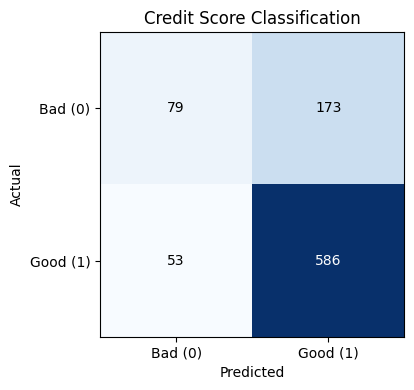

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- 0. Download Dataset and Ensure Correct 1/0 Mapping ----
csv_filename = 'GermanCredit.csv'

# Force re-download or process because the current file on disk has incorrect labels [1, 2]
print("Downloading and parsing German Credit dataset with correct 1/0 mapping...")
# Standard backup/primary URL from Gastonstat containing Status/credit_risk labeled with 1 and 2
url = 'https://raw.githubusercontent.com/gastonstat/CreditScoring/master/CreditScoring.csv'
try:
    df_temp = pd.read_csv(url)
    # Map target column to 'credit_risk'
    if 'Status' in df_temp.columns:
        df_temp.rename(columns={'Status': 'credit_risk'}, inplace=True)

    # The dataset uses: 1 = good credit, 2 = bad credit
    # We must explicitly convert this to 1 = good credit, 0 = bad credit
    df_temp['credit_risk'] = df_temp['credit_risk'].map({1: 1, 2: 0})

    # Remove rows where target is missing or invalid (e.g. 0 was used for unknown in some mirrors)
    df_temp = df_temp[df_temp['credit_risk'].isin([0, 1])]
    df_temp['credit_risk'] = df_temp['credit_risk'].astype(int)

    df_temp.to_csv(csv_filename, index=False)
    print("Dataset downloaded and preprocessed successfully.")
except Exception as e:
    print(f"Failed to process dataset: {e}")

# ---- 1. Load CSV ----
df = pd.read_csv(csv_filename)
print("Rows:", len(df), " Columns:", df.shape[1])
print("Good credit (1):", int((df['credit_risk'] == 1).sum()),
      " Bad credit (0):", int((df['credit_risk'] == 0).sum()), "\n")

y = df['credit_risk'].values
features = df.drop(columns='credit_risk')

# ---- 2. Convert text columns to numbers (one-hot encoding) ----
X_df = pd.get_dummies(features, dtype=float)
print("Features after encoding:", X_df.shape[1], "\n")
X = X_df.values

# ---- 3. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]

# ---- 4. Standardize (using training mean and std) ----
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
sd[sd == 0] = 1
Xtr = (Xtr - mu) / sd
Xte = (Xte - mu) / sd
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 5. Logistic Regression (gradient descent) ----
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.zeros(Xtr.shape[1])
b = 0.0
lr, epochs, lam = 0.1, 1000, 0.01          # lam = small penalty to avoid overfitting

for epoch in range(1, epochs + 1):
    p = sigmoid(Xtr @ w + b)
    loss = -np.mean(ytr * np.log(p + 1e-12) + (1 - ytr) * np.log(1 - p + 1e-12))
    w -= lr * (Xtr.T @ (p - ytr) / len(ytr) + lam * w)
    b -= lr * np.mean(p - ytr)
    if epoch == 1 or epoch % 250 == 0:
        print(f"Epoch {epoch:4d}  Loss = {loss:.4f}")

def predict(Xin):
    return (sigmoid(Xin @ w + b) >= 0.5).astype(int)

pred = predict(Xte)

# ---- 6. Confusion matrix ----
cm = np.zeros((2, 2), dtype=int)
for a, p_ in zip(yte, pred):
    cm[a, p_] += 1

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=['Bad (0)', 'Good (1)'], columns=['Bad (0)', 'Good (1)']))

# ---- 7. Accuracy, precision, recall, F1 ----
accuracy = np.trace(cm) / cm.sum() * 100
print(f"\nTrain accuracy: {np.mean(predict(Xtr) == ytr) * 100:.2f}%")
print(f"Test accuracy:  {accuracy:.2f}%")
print("\nClass      Precision  Recall  F1")
for i, name in enumerate(['Bad (0)', 'Good (1)']):
    prec = cm[i, i] / cm[:, i].sum() if cm[:, i].sum() > 0 else 0
    rec = cm[i, i] / cm[i, :].sum() if cm[i, :].sum() > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    print(f"{name:<10} {prec:.2f}       {rec:.2f}    {f1:.2f}")

# ---- 8. Top factors that decide credit risk ----
weights = pd.Series(w, index=X_df.columns)
print("\nTop 5 factors for GOOD credit:")
print(weights.sort_values(ascending=False).head(5).round(3).to_string())
print("\nTop 5 factors for BAD credit:")
print(weights.sort_values().head(5).round(3).to_string())

# ---- 9. Plot the confusion matrix ----
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Bad (0)', 'Good (1)'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Bad (0)', 'Good (1)'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Credit Score Classification')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()